# IES Ponte Tech — análise para a diretoria

Este notebook traz exemplos executáveis de leitura, criação de um dataset, um gráfico e um relatório PDF. Eles mostram como começar; o grupo deve construir os enriquecimentos e as respostas do case. Leia o case e o dicionário antes de analisar. Todos os dados são simulados.

Execute as células em ordem. No Jupyter ou VS Code, abra o notebook na pasta extraída `IES_Ponte_Tech`. No Colab, extraia o pacote e ajuste o diretório de trabalho para essa pasta. As saídas são salvas em `saidas/`.

## 1. Ler as cinco bases

O separador é ponto e vírgula. Ler como texto preserva identificadores e permite avaliar os formatos antes de converter valores. `keep_default_na=False` mantém campos vazios como texto vazio. Se as bibliotecas não estiverem instaladas, prepare o ambiente com `pip install -r requirements.txt` antes da aula.

In [1]:
from pathlib import Path
import textwrap
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.backends.backend_pdf import PdfPages

RAIZ = next((p for p in [Path.cwd(), Path.cwd() / 'IES_Ponte_Tech']
             if (p / 'dados/alunos.csv').exists()), None)
if RAIZ is None:
    raise FileNotFoundError('Extraia todo o ZIP e abra o notebook na pasta IES_Ponte_Tech.')

SAIDAS = RAIZ / 'saidas'
SAIDAS.mkdir(exist_ok=True)
nomes = ['alunos', 'domicilios', 'beneficios', 'empresas', 'frequencia']
bases = {nome: pd.read_csv(RAIZ / 'dados' / f'{nome}.csv', sep=';',
                          encoding='utf-8-sig', dtype=str, keep_default_na=False)
         for nome in nomes}
for nome, base in bases.items():
    print(f'{nome}: {base.shape[0]:,} linhas e {base.shape[1]} colunas')


alunos: 8,120 linhas e 13 colunas
domicilios: 6,260 linhas e 5 colunas
beneficios: 12,995 linhas e 5 colunas
empresas: 80 linhas e 6 colunas
frequencia: 96,400 linhas e 4 colunas


In [2]:
bases['alunos'].head(10)


,aluno_id,domicilio_id,curso,semestre,turno,data_nascimento,tempo_ida_min,modal_transporte,empresa_id,empresa_declarada,tipo_vinculo,horas_trabalho_semana,situacao_30_set
0,A05462,D02203,Análise e Desenvolvimento de Sistemas,6,Noite,10/05/1998,46,Trem/Metrô,E012,"Sou da Quentara Laboratório Digital, não confu...",Estágio,40,Ativo
1,A02433,D00583,Ciência da Computação,1,Noite,05-04-2002,77,Ônibus,E048,Novéris Soluções Integradas,Estágio,20,Ativo
2,A04910,D04419,Sistemas de Informação,2,Manhã,19/10/1988,20,Carro,E013,Quentara,Estágio,20,Ativo
3,A01264,D02602,SIS,6,Noite,2002-10-09,53,Carro,E036,Projeto Orbisque 1,Estágio,30,Ativo
4,A06217,D02485,ADS - tecnologia,1,Manhã,28/01/1999,8,Carro,E016,Aurivexa Sistemas / unidade paulista,CLT,20,Ativo
5,A01080,D01496,Sistemas Informacao,6,Noite,1987-01-25,61,Ônibus,,,Sem vínculo,0,Ativo
6,a02245,D01834,C. da Computação,2,noite,10-07-2005,108,Carro,E034,Projeto Trivelia 4 — agora Trivélia Serviços A...,CLT,20,Ativo
7,A05099,D02739,Ciência Computação,5,Manhã,1985-12-26,130,Trem/Metrô,E004,Nuváris Serviços Analíticos LTDA,Estágio,40,Ativo
8,A05504,D00197,CCO,5,Manhã,2005-09-29,112,Ônibus,,,Sem vínculo,0,Ativo
9,A03223,D02489,sistemas de informação - bacharelado,5,Manhã,07/10/2006,73,Carro,E034,"Acho que e Trivelia, entrei pelo contato da Ju...",Estágio,20,ativo


In [3]:
# Troque 'alunos' por qualquer outra base para inspecioná-la.
bases['frequencia'].info()


<class 'pandas.DataFrame'>
RangeIndex: 96400 entries, 0 to 96399
Data columns (total 4 columns):
 #   Column           Non-Null Count  Dtype
---  ------           --------------  -----
 0   aluno_id         96400 non-null  str  
 1   semana           96400 non-null  str  
 2   aulas_previstas  96400 non-null  str  
 3   aulas_presentes  96400 non-null  str  
dtypes: str(4)
memory usage: 2.9 MB


## 2. Criar e salvar um dataset de trabalho

Um dataset pode ser um DataFrame com as colunas necessárias à análise. Este exemplo copia o cadastro, retira apenas repetições exatas e padroniza o turno. As demais decisões de tratamento e os cruzamentos continuam sendo responsabilidade do grupo.

A base enriquecida final deverá incorporar os atributos necessários às perguntas da diretoria. Este exemplo ainda não calcula renda por pessoa, idade, benefícios, frequência ou contexto das empresas.

In [4]:
colunas = ['aluno_id', 'domicilio_id', 'curso', 'semestre', 'turno',
           'data_nascimento', 'tempo_ida_min', 'modal_transporte',
           'empresa_id', 'empresa_declarada', 'tipo_vinculo',
           'horas_trabalho_semana', 'situacao_30_set']

dataset = bases['alunos'].drop_duplicates().loc[:, colunas].copy()
dataset['turno_padronizado'] = dataset['turno'].str.strip().str.title()

print(f'Dataset inicial: {len(dataset):,} linhas')
dataset.head()


Dataset inicial: 8,000 linhas


,aluno_id,domicilio_id,curso,semestre,turno,data_nascimento,tempo_ida_min,modal_transporte,empresa_id,empresa_declarada,tipo_vinculo,horas_trabalho_semana,situacao_30_set,turno_padronizado
0,A05462,D02203,Análise e Desenvolvimento de Sistemas,6,Noite,10/05/1998,46,Trem/Metrô,E012,"Sou da Quentara Laboratório Digital, não confu...",Estágio,40,Ativo,Noite
1,A02433,D00583,Ciência da Computação,1,Noite,05-04-2002,77,Ônibus,E048,Novéris Soluções Integradas,Estágio,20,Ativo,Noite
2,A04910,D04419,Sistemas de Informação,2,Manhã,19/10/1988,20,Carro,E013,Quentara,Estágio,20,Ativo,Manhã
3,A01264,D02602,SIS,6,Noite,2002-10-09,53,Carro,E036,Projeto Orbisque 1,Estágio,30,Ativo,Noite
4,A06217,D02485,ADS - tecnologia,1,Manhã,28/01/1999,8,Carro,E016,Aurivexa Sistemas / unidade paulista,CLT,20,Ativo,Manhã


In [5]:
# CSV de exemplo. Não substitui a base enriquecida final do grupo.
arquivo_dataset = SAIDAS / 'dataset_inicial.csv'
dataset.to_csv(arquivo_dataset, sep=';', encoding='utf-8-sig', index=False)
print('Dataset salvo em:', arquivo_dataset)


Dataset salvo em: /home/vinicius-aoki/Documents/SPTech/Semestre5/Analise-Dados/pacote_atividade/saidas/dataset_inicial.csv


## 3. Gerar um gráfico (exemplo)

O gráfico mostra a quantidade de registros do cadastro por turno após remover repetições exatas. Antes de usá-lo como número de alunos, confira se cada pessoa aparece uma única vez. O exemplo não responde às perguntas de renda, benefícios ou permanência.

Para adaptar, substitua a tabulação pela medida e pelo recorte que respondem à sua pergunta. Mantenha título, unidade, período e população claros.

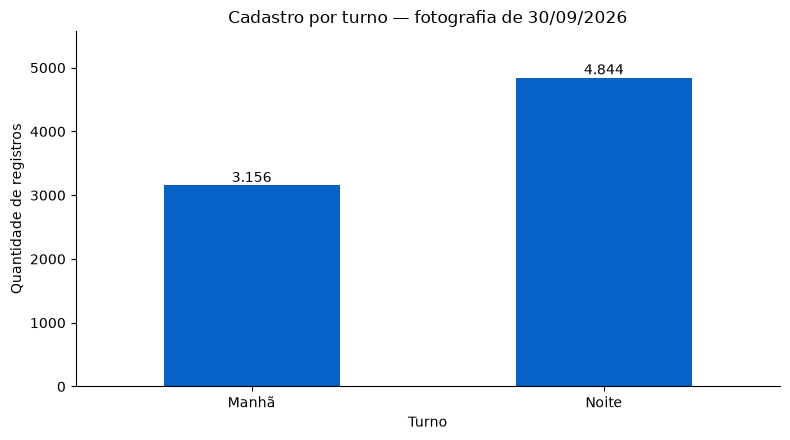

Gráfico salvo em: /home/vinicius-aoki/Documents/SPTech/Semestre5/Analise-Dados/pacote_atividade/saidas/grafico_exemplo_turno.png


In [6]:
contagem_turno = dataset['turno_padronizado'].replace('', 'Não informado').value_counts().sort_index()

fig_grafico, ax = plt.subplots(figsize=(8, 4.5))
contagem_turno.plot(kind='bar', ax=ax, color='#0762C8', rot=0)
ax.set_title('Cadastro por turno — fotografia de 30/09/2026')
ax.set_xlabel('Turno')
ax.set_ylabel('Quantidade de registros')
ax.spines[['top', 'right']].set_visible(False)
for posicao, valor in enumerate(contagem_turno):
    ax.text(posicao, valor, f'{valor:,}'.replace(',', '.'), ha='center', va='bottom')
ax.margins(y=0.15)
fig_grafico.tight_layout()
arquivo_grafico = SAIDAS / 'grafico_exemplo_turno.png'
fig_grafico.savefig(arquivo_grafico, dpi=180, bbox_inches='tight')
plt.show()
print('Gráfico salvo em:', arquivo_grafico)


## 4. Criar um relatório PDF

`PdfPages` salva figuras do Matplotlib como páginas de um PDF, sem uma biblioteca adicional de PDF. Este exemplo produz uma página de texto e outra com o gráfico anterior. Ele não é o relatório final: substitua os textos por respostas fundamentadas e acrescente os gráficos de sua equipe.

Edite `resposta`, `insight` e `limitacao` antes de exportar a versão final. Para incluir outro gráfico, use `pdf.savefig(sua_figura)` dentro do bloco `with`.

In [7]:
titulo = 'IES Ponte Tech — relatório de exemplo'
pergunta = 'Exemplo técnico: como os registros do cadastro se distribuem por turno?'
resposta = 'Preencher com a resposta e os números verificados pela equipe.'
insight = 'Preencher com a implicação para uma decisão da diretoria.'
limitacao = ('Este exemplo remove repetições exatas e padroniza somente o turno. '
             'Os demais tratamentos, enriquecimentos e indicadores ainda precisam ser construídos.')

arquivo_pdf = SAIDAS / 'relatorio_exemplo.pdf'
with PdfPages(arquivo_pdf) as pdf:
    fig_texto = plt.figure(figsize=(8.27, 11.69))
    fig_texto.text(0.08, 0.93, titulo, fontsize=19, color='#0762C8', weight='bold')
    blocos = [
        ('Contexto', 'Dados simulados. Fotografia acadêmica de 30/09/2026.'),
        ('Pergunta', pergunta),
        ('Resposta', resposta),
        ('Insight', insight),
        ('Limitação', limitacao),
        ('Fonte e método', 'alunos.csv; retirada de repetições exatas e padronização de turno.')
    ]
    y = 0.85
    for subtitulo, texto in blocos:
        fig_texto.text(0.08, y, subtitulo, fontsize=12, weight='bold')
        linhas = textwrap.wrap(texto, width=83)
        fig_texto.text(0.08, y - 0.025, '\n'.join(linhas), fontsize=10, va='top', linespacing=1.5)
        y -= 0.055 + len(linhas) * 0.023
    pdf.savefig(fig_texto)
    plt.close(fig_texto)
    pdf.savefig(fig_grafico)
print('Relatório PDF salvo em:', arquivo_pdf)


Relatório PDF salvo em: /home/vinicius-aoki/Documents/SPTech/Semestre5/Analise-Dados/pacote_atividade/saidas/relatorio_exemplo.pdf


## Agora, a análise da equipe

Os exemplos acima são um ponto de partida. Definam o grão do dataset final, as regras para campos insuficientes e as correspondências entre as fontes. Registrem a origem dos atributos acrescentados. O painel final deve responder às perguntas do case, com indicadores, gráficos, insights e três prioridades.

In [8]:
# Espaço de trabalho da equipe.
import unicodedata

def numero(texto):
    serie = texto.astype(str).str.strip()
    ambos = serie.str.contains(',', regex=False) & serie.str.contains('.', regex=False)
    serie = serie.where(~ambos, serie.str.replace('.', '', regex=False))
    return pd.to_numeric(serie.str.replace(',', '.', regex=False), errors='coerce')

def curso_padrao(valor):
    texto = ''.join(c for c in unicodedata.normalize('NFKD', str(valor).strip().lower()) if not unicodedata.combining(c))
    compacto = ''.join(c for c in texto if c.isalnum())
    if 'comput' in compacto or compacto in {'cc', 'cco'}:
        return 'Ciência da Computação'
    if 'sistemainform' in compacto or compacto in {'si', 'sis', 'sistinf'}:
        return 'Sistemas de Informação'
    if 'ads' in compacto or ('desenvolv' in compacto and 'sistem' in compacto):
        return 'Análise e Desenvolvimento de Sistemas'
    return str(valor).strip() or 'Não informado'

alunos = bases['alunos'].drop_duplicates().copy()
domicilios = bases['domicilios'].drop_duplicates().copy()
empresas = bases['empresas'].drop_duplicates().copy()
for tabela, colunas_id in [(alunos, ['aluno_id', 'domicilio_id', 'empresa_id']), (domicilios, ['domicilio_id']), (empresas, ['empresa_id'])]:
    for coluna in colunas_id:
        tabela[coluna] = tabela[coluna].astype(str).str.strip().str.upper()


## Enriquecimento
Que informação nova é necessária? Qual sua origem e regra?

In [9]:
# Espaço de trabalho da equipe.
alunos['curso_padronizado'] = alunos['curso'].map(curso_padrao)
alunos['turno_padronizado'] = alunos['turno'].str.strip().str.title().replace('', 'Não informado')
alunos['data_nascimento_dt'] = pd.to_datetime(alunos['data_nascimento'].str.strip(), dayfirst=True, format='mixed', errors='coerce')
referencia = pd.Timestamp('2026-09-30')
aniversario_passou = (alunos['data_nascimento_dt'].dt.month > referencia.month) | ((alunos['data_nascimento_dt'].dt.month == referencia.month) & (alunos['data_nascimento_dt'].dt.day >= referencia.day))
alunos['idade_30_set'] = referencia.year - alunos['data_nascimento_dt'].dt.year - (~aniversario_passou).astype('Int64')
alunos['tempo_ida_min_num'] = numero(alunos['tempo_ida_min'])
alunos['horas_trabalho_semana_num'] = numero(alunos['horas_trabalho_semana'])
domicilios['renda_familiar_num'] = numero(domicilios['renda_familiar_mensal'])
domicilios['moradores_num'] = pd.to_numeric(domicilios['moradores'], errors='coerce')
domicilios['renda_por_pessoa'] = domicilios['renda_familiar_num'].div(domicilios['moradores_num'].where(domicilios['moradores_num'] > 0))
def faixa_renda(valor):
    if pd.isna(valor): return 'Indeterminada'
    if valor <= 700: return 'E'
    if valor <= 1400: return 'D'
    if valor <= 2800: return 'C'
    if valor <= 5600: return 'B'
    return 'A'
domicilios['faixa_renda'] = domicilios['renda_por_pessoa'].map(faixa_renda)
beneficios = bases['beneficios'].drop_duplicates().copy()
beneficios['valor_mensal_num'] = numero(beneficios['valor_mensal'])
beneficios_agg = (beneficios.groupby(['aluno_id', 'tipo_beneficio'], as_index=False)['valor_mensal_num'].sum()
                   .pivot(index='aluno_id', columns='tipo_beneficio', values='valor_mensal_num').fillna(0).reset_index())
beneficios_agg.columns.name = None
beneficios_agg = beneficios_agg.rename(columns={'Auxílio permanência': 'auxilio_permanencia_valor', 'Vale-transporte': 'vale_transporte_valor'})
freq = bases['frequencia'].drop_duplicates().copy()
freq['aulas_previstas_num'] = numero(freq['aulas_previstas'])
freq['aulas_presentes_num'] = numero(freq['aulas_presentes'])
freq_agg = freq.groupby('aluno_id', as_index=False)[['aulas_previstas_num', 'aulas_presentes_num']].sum()
freq_agg['frequencia_pct'] = np.where(freq_agg['aulas_previstas_num'] > 0, 100 * freq_agg['aulas_presentes_num'] / freq_agg['aulas_previstas_num'], np.nan)
dataset = (alunos.merge(domicilios[['domicilio_id', 'renda_por_pessoa', 'faixa_renda', 'regiao', 'tipo_moradia']], on='domicilio_id', how='left')
           .merge(empresas[['empresa_id', 'empresa_nome', 'setor', 'porte', 'conveniada']], on='empresa_id', how='left')
           .merge(beneficios_agg, on='aluno_id', how='left').merge(freq_agg, on='aluno_id', how='left'))
for coluna in ['auxilio_permanencia_valor', 'vale_transporte_valor']:
    if coluna not in dataset: dataset[coluna] = 0.0
    dataset[coluna] = dataset[coluna].fillna(0)
dataset['recebe_auxilio_permanencia'] = dataset['auxilio_permanencia_valor'] > 0
dataset['recebe_vale_transporte'] = dataset['vale_transporte_valor'] > 0
dataset['vinculo_profissional'] = ~dataset['tipo_vinculo'].str.strip().str.lower().eq('sem vínculo')
dataset['deslocamento_alto'] = dataset['tempo_ida_min_num'] > 90
dataset['grupo_menor_renda'] = dataset['faixa_renda'].isin(['D', 'E'])
dataset['situacao_risco_permanencia'] = dataset['situacao_30_set'].isin(['Trancado', 'Desistente'])
dataset['faixa_deslocamento'] = pd.cut(dataset['tempo_ida_min_num'], [-np.inf, 30, 60, 90, np.inf], labels=['Até 30 min', '31–60 min', '61–90 min', 'Mais de 90 min'])
dataset['faixa_carga_trabalho'] = pd.cut(dataset['horas_trabalho_semana_num'], [-np.inf, 0, 20, 30, np.inf], labels=['Sem trabalho', 'Até 20 h', '21–30 h', 'Mais de 30 h'])
arquivo_enriquecido = SAIDAS / 'dataset_enriquecido.csv'
dataset.to_csv(arquivo_enriquecido, sep=';', encoding='utf-8-sig', index=False)
print(f'Dataset enriquecido: {len(dataset):,} alunos; classificação de renda disponível para {(dataset.faixa_renda != "Indeterminada").sum():,}.')
display(dataset.head())


Dataset enriquecido: 8,000 alunos; classificação de renda disponível para 7,841.


,aluno_id,domicilio_id,curso,semestre,turno,data_nascimento,tempo_ida_min,modal_transporte,empresa_id,empresa_declarada,...,aulas_presentes_num,frequencia_pct,recebe_auxilio_permanencia,recebe_vale_transporte,vinculo_profissional,deslocamento_alto,grupo_menor_renda,situacao_risco_permanencia,faixa_deslocamento,faixa_carga_trabalho
0,A05462,D02203,Análise e Desenvolvimento de Sistemas,6,Noite,10/05/1998,46,Trem/Metrô,E012,"Sou da Quentara Laboratório Digital, não confu...",...,127,73.837209,False,False,True,False,False,False,31–60 min,Mais de 30 h
1,A02433,D00583,Ciência da Computação,1,Noite,05-04-2002,77,Ônibus,E048,Novéris Soluções Integradas,...,138,88.461538,False,False,True,False,False,False,61–90 min,Até 20 h
2,A04910,D04419,Sistemas de Informação,2,Manhã,19/10/1988,20,Carro,E013,Quentara,...,135,73.369565,True,True,True,False,True,False,Até 30 min,Até 20 h
3,A01264,D02602,SIS,6,Noite,2002-10-09,53,Carro,E036,Projeto Orbisque 1,...,153,83.152174,False,True,True,False,False,False,31–60 min,21–30 h
4,A06217,D02485,ADS - tecnologia,1,Manhã,28/01/1999,8,Carro,E016,Aurivexa Sistemas / unidade paulista,...,187,99.468085,False,True,True,False,False,False,Até 30 min,Até 20 h


## 1. Quem são nossos alunos?
Qual é o percentual de alunos em cada faixa de renda que a diretoria chama de “classe social”? Como o perfil varia por curso e turno? Quantos alunos não podem ser classificados com segurança?

In [10]:
# Espaço de trabalho da equipe.
ordem_faixas = ['A', 'B', 'C', 'D', 'E', 'Indeterminada']
perfil_renda = dataset['faixa_renda'].value_counts().reindex(ordem_faixas, fill_value=0).rename('alunos').to_frame()
perfil_renda['percentual_do_total'] = 100 * perfil_renda['alunos'] / len(dataset)
print('1. Perfil dos alunos por faixa interna de renda mensal por pessoa (denominador: todos os alunos)')
display(perfil_renda.round(2))
print('Perfil por curso e turno:')
display(pd.crosstab([dataset['curso_padronizado'], dataset['turno_padronizado']], dataset['faixa_renda'], normalize='index').mul(100).round(1))
print(f"Não classificados com segurança: {(dataset['faixa_renda'] == 'Indeterminada').sum():,} ({100 * (dataset['faixa_renda'] == 'Indeterminada').mean():.1f}%).")


1. Perfil dos alunos por faixa interna de renda mensal por pessoa (denominador: todos os alunos)


,alunos,percentual_do_total
faixa_renda,,
A,604,7.55
B,1172,14.65
C,1874,23.42
D,2131,26.64
E,2040,25.50
Indeterminada,159,1.99


Perfil por curso e turno:


faixa_renda                                                 A     B     C  \
curso_padronizado                     turno_padronizado                     
Análise e Desenv de Sist.             Manhã               8.1  14.0  23.3   
                                      Noite               4.9  17.6  22.5   
Análise e Desenvolvimento de Sistemas Manhã               8.3  15.7  22.2   
                                      Noite               6.7  14.2  25.4   
Análise/Desenv. Sistemas              Manhã               8.1  17.4  19.8   
                                      Noite               6.6  16.2  24.3   
Bacharelado em Sistemas de Informação Manhã               8.2  17.5  15.5   
                                      Noite               7.4  14.1  22.8   
Ciência da Computação                 Manhã               7.4  14.3  23.7   
                                      Noite               8.2  14.1  22.8   
Sist de Inf                           Manhã               6.4  16.0  21.3   
                                      Noite               7.4  14.7  22.1   
Sist. de Informação                   Manhã               8.0  14.8  22.7   
                                      Noite               6.8  15.2  22.0   
Sistema de Informação                 Manhã               7.2  14.4  20.8   
                                      Noite              13.3  11.3  19.3   
Sistemas Informacao                   Manhã               6.2  17.7  19.8   
                                      Noite               5.3  15.0  30.8   
Sistemas de Informação                Manhã               7.3  12.7  24.1   
                                      Noite               7.3  16.7  24.9   
sistemas de informacao                Manhã              10.3  10.3  18.4   
                                      Noite               8.6  16.4  25.7   
sistemas de informação - bacharelado  Manhã               4.7   9.3  27.1   
                                      Noite               7.8  17.1  24.8   

faixa_renda                                                 D     E  \
curso_padronizado                     turno_padronizado               
Análise e Desenv de Sist.             Manhã              23.3  26.7   
                                      Noite              23.9  29.6   
Análise e Desenvolvimento de Sistemas Manhã              27.8  23.8   
                                      Noite              26.6  25.3   
Análise/Desenv. Sistemas              Manhã              30.2  22.1   
                                      Noite              26.5  24.3   
Bacharelado em Sistemas de Informação Manhã              28.9  27.8   
                                      Noite              25.5  27.5   
Ciência da Computação                 Manhã              26.5  26.1   
                                      Noite              26.7  25.5   
Sist de Inf                           Manhã              30.9  23.4   
                                      Noite              26.4  28.8   
Sist. de Informação                   Manhã              26.1  26.1   
                                      Noite              25.0  31.1   
Sistema de Informação                 Manhã              27.2  28.8   
                                      Noite              27.3  28.0   
Sistemas Informacao                   Manhã              31.2  22.9   
                                      Noite              24.1  22.6   
Sistemas de Informação                Manhã              28.2  24.9   
                                      Noite              24.9  24.6   
sistemas de informacao                Manhã              33.3  26.4   
                                      Noite              22.9  26.4   
sistemas de informação - bacharelado  Manhã              29.9  26.2   
                                      Noite              23.3  25.6   

faixa_renda                                              Indeterminada  
curso_padronizado                     turno_padronizado                 
Anál

Não classificados com segurança: 159 (2.0%).


## 2. Quem enfrenta maior deslocamento?
Qual é o tempo típico de ida à IES e qual percentual leva mais de 90 minutos? Onde estão esses alunos? Como o deslocamento se relaciona com frequência e situação acadêmica?

In [11]:
# Espaço de trabalho da equipe.
mediana_ida = dataset['tempo_ida_min_num'].median()
deslocamento = pd.DataFrame({'alunos': [len(dataset), dataset['deslocamento_alto'].sum()], 'percentual': [100, 100 * dataset['deslocamento_alto'].mean()]}, index=['Total', 'Mais de 90 min'])
print(f'2. Tempo típico de ida: mediana de {mediana_ida:.0f} minutos; média de {dataset["tempo_ida_min_num"].mean():.1f} minutos.')
display(deslocamento.round(2))
print('Regiões entre os alunos com deslocamento acima de 90 minutos:')
display(dataset.loc[dataset['deslocamento_alto'], 'regiao'].value_counts().rename('alunos').to_frame())
print('Deslocamento, frequência e situação acadêmica:')
display(dataset.groupby('deslocamento_alto').agg(alunos=('aluno_id', 'size'), frequencia_media_pct=('frequencia_pct', 'mean'), trancados_ou_desistentes_pct=('situacao_risco_permanencia', 'mean')).assign(trancados_ou_desistentes_pct=lambda x: 100*x['trancados_ou_desistentes_pct']).round(2))


2. Tempo típico de ida: mediana de 60 minutos; média de 62.3 minutos.


,alunos,percentual
Total,8000,100.00
Mais de 90 min,1058,13.23


Regiões entre os alunos com deslocamento acima de 90 minutos:


,alunos
regiao,
Grande SP,576
Leste,176
Sul,114
Norte,90
Oeste,60
Centro,38


Deslocamento, frequência e situação acadêmica:


,alunos,frequencia_media_pct,trancados_ou_desistentes_pct
deslocamento_alto,,,
False,6942,87.22,9.71
True,1058,77.31,14.18


## 3. Os benefícios chegam a quem mais precisa?
Qual percentual recebe cada benefício e qual valor mensal é destinado aos alunos? Entre os de menor renda e maior deslocamento, quantos não recebem auxílio permanência ou vale-transporte? Há diferenças entre cursos e turnos?

In [ ]:
# Espaço de trabalho da equipe.
beneficio_cols = ['recebe_auxilio_permanencia', 'recebe_vale_transporte']
cobertura = pd.DataFrame({'alunos': [dataset[c].sum() for c in beneficio_cols], 'percentual': [100 * dataset[c].mean() for c in beneficio_cols], 'valor_total_mensal': [dataset[c.replace('recebe_', '') + '_valor'].sum() for c in beneficio_cols]}, index=['Auxílio permanência', 'Vale-transporte'])
print('3. Cobertura e valor mensal dos benefícios (alunos distintos por benefício):')
display(cobertura.round(2))
alvo = dataset['grupo_menor_renda'] & dataset['deslocamento_alto']
print(f'Alunos simultaneamente nas faixas D/E e com deslocamento alto: {alvo.sum():,}.')
display(pd.DataFrame({'não recebe auxílio permanência': [((~dataset.loc[alvo, "recebe_auxilio_permanencia"]).sum())], 'não recebe vale-transporte': [(~dataset.loc[alvo, "recebe_vale_transporte"]).sum()]}, index=['alunos']))
print('Cobertura por curso e turno:')
display(dataset.groupby(['curso_padronizado', 'turno_padronizado'])[beneficio_cols].mean().mul(100).round(1))


3. Cobertura e valor mensal dos benefícios (alunos distintos por benefício):


,alunos,percentual,valor_total_mensal
Auxílio permanência,1806,22.58,547100.0
Vale-transporte,4683,58.54,1264860.0


Alunos simultaneamente nas faixas D/E e com deslocamento alto: 546.


,não recebe auxílio permanência,não recebe vale-transporte
alunos,294,227


Cobertura por curso e turno:


recebe_auxilio_permanencia  \
curso_padronizado                     turno_padronizado                               
Análise e Desenv de Sist.             Manhã                                    18.6   
                                      Noite                                    16.2   
Análise e Desenvolvimento de Sistemas Manhã                                    21.7   
                                      Noite                                    23.6   
Análise/Desenv. Sistemas              Manhã                                    23.3   
                                      Noite                                    21.9   
Bacharelado em Sistemas de Informação Manhã                                    24.7   
                                      Noite                                    22.1   
Ciência da Computação                 Manhã                                    23.4   
                                      Noite                                    22.1   
Sist de Inf                           Manhã                                    19.1   
                                      Noite                                    24.4   
Sist. de Informação                   Manhã                                    15.9   
                                      Noite                                    24.1   
Sistema de Informação                 Manhã                                    25.6   
                                      Noite                                    29.3   
Sistemas Informacao                   Manhã                                    26.0   
                                      Noite                                    21.1   
Sistemas de Informação                Manhã                                    22.5   
                                      Noite                                    22.7   
sistemas de informacao                Manhã                                    21.6   
                                      Noite                                    20.7   
sistemas de informação - bacharelado  Manhã                                    20.6   
                                      Noite                                    20.9   

                                                         recebe_vale_transporte  
curso_padronizado                     turno_padronizado                          
Análise e Desenv de Sist.             Manhã                                65.1  
                                      Noite                                62.0  
Análise e Desenvolvimento de Sistemas Manhã                                58.5  
                                      Noite                                58.7  
Análise/Desenv. Sistemas              Manhã                                58.1  
                                      Noite                                62.0  
Bacharelado em Sistemas de Informação Manhã                                55.7  
                                      Noite                                50.3  
Ciência da Computação                 Manhã                                60.1  
                                      Noite                                57.0  
Sist de Inf                           Manhã                                61.7  
                                      Noite                                59.8  
Sist. de Informação                   Manhã                                59.1  
                                      Noite                                54.1  
Sistema de Informação                 Manhã                                65.6  
                                      Noite                                54.0  
Sistemas Informacao                   Manhã                                58.3  
                                      Noite                                63.9  
Sistemas de Informação                Manhã                                56.2  
                                      Noite                             

## 4. Como as empresas participam da formação?
Qual percentual tem vínculo profissional? Quais empresas e setores concentram esses alunos? Como carga de trabalho, benefícios, frequência e situação acadêmica diferem entre empresas? Quais parcerias merecem uma conversa prioritária?

In [13]:
# Espaço de trabalho da equipe.
vinculados = dataset[dataset['vinculo_profissional']].copy()
print(f'4. Vínculo profissional: {len(vinculados):,} de {len(dataset):,} alunos ({100 * len(vinculados) / len(dataset):.1f}%).')
print('Empresas e setores que concentram alunos vinculados:')
empresas_resumo = vinculados.groupby(['empresa_id', 'empresa_nome', 'setor'], dropna=False).agg(alunos=('aluno_id', 'size'), carga_media_h=('horas_trabalho_semana_num', 'mean'), frequencia_media_pct=('frequencia_pct', 'mean'), risco_permanencia_pct=('situacao_risco_permanencia', 'mean')).reset_index()
empresas_resumo['risco_permanencia_pct'] *= 100
display(empresas_resumo.sort_values('alunos', ascending=False).head(15).round(2))
print('Comparação por empresa: benefícios e situação acadêmica; empresas não identificadas permanecem visíveis.')
display(vinculados.groupby('empresa_id', dropna=False).agg(alunos=('aluno_id', 'size'), conveniada=('conveniada', 'first'), valor_beneficios=('auxilio_permanencia_valor', 'sum'), frequencia_media_pct=('frequencia_pct', 'mean'), risco_permanencia_pct=('situacao_risco_permanencia', 'mean')).assign(risco_permanencia_pct=lambda x: 100*x['risco_permanencia_pct']).sort_values('alunos', ascending=False).head(15).round(2))
print('A conversa prioritária deve começar por empresas com maior concentração, baixa frequência ou maior risco; isto é associação, não causalidade.')


4. Vínculo profissional: 5,842 de 8,000 alunos (73.0%).
Empresas e setores que concentram alunos vinculados:


,empresa_id,empresa_nome,setor,alunos,carga_media_h,frequencia_media_pct,risco_permanencia_pct
0,,NaN,NaN,650,33.45,86.59,9.85
22,E022,Lumétris Laboratório Digital,Finanças,105,33.47,86.74,11.43
31,E031,Trivélia Sistemas,Consultoria,105,31.90,85.75,12.38
35,E035,Trivélia Tecnologia Aplicada,Indústria,101,32.22,86.29,11.88
21,E021,Lumétris Sistemas,Consultoria,100,33.16,84.98,17.00
39,E039,Orbisque Serviços Analíticos,Tecnologia,99,33.25,87.22,14.14
7,E007,Velúmina Laboratório Digital,Tecnologia,99,33.84,84.76,12.12
25,E025,Lumétris Tecnologia Aplicada,Consultoria,98,34.67,86.05,12.24
36,E036,Orbisque Sistemas,Indústria,97,35.73,85.82,12.37
24,E024,Lumétris Serviços Analíticos,Indústria,97,34.31,86.34,11.34


Comparação por empresa: benefícios e situação acadêmica; empresas não identificadas permanecem visíveis.


,alunos,conveniada,valor_beneficios,frequencia_media_pct,risco_permanencia_pct
empresa_id,,,,,
,650,NaN,44100.0,86.59,9.85
E022,105,Sim,7200.0,86.74,11.43
E031,105,Sim,9600.0,85.75,12.38
E035,101,Sim,6400.0,86.29,11.88
E021,100,Sim,5800.0,84.98,17.00
E039,99,Sim,5500.0,87.22,14.14
E007,99,Sim,7400.0,84.76,12.12
E025,98,Sim,6500.0,86.05,12.24
E036,97,Sim,6800.0,85.82,12.37


A conversa prioritária deve começar por empresas com maior concentração, baixa frequência ou maior risco; isto é associação, não causalidade.


## 5. Quais grupos exigem atenção à permanência?
Como as proporções de trancamento e desistência variam com renda, deslocamento e carga de trabalho? Qual combinação reúne maior percentual e maior número de alunos nessas situações? A associação permanece dentro de curso ou turno?

In [14]:
# Espaço de trabalho da equipe.
dataset['combinacao_risco'] = dataset['faixa_renda'].where(dataset['faixa_renda'].isin(['D', 'E']), 'Outras/indeterminada') + ' | ' + dataset['faixa_deslocamento'].astype(str) + ' | ' + dataset['faixa_carga_trabalho'].astype(str)
risco = dataset.groupby('combinacao_risco', dropna=False).agg(alunos=('aluno_id', 'size'), casos=('situacao_risco_permanencia', 'sum'), proporcao_pct=('situacao_risco_permanencia', 'mean')).reset_index()
risco['proporcao_pct'] *= 100
print('5. Grupos de atenção à permanência, ordenados por número de casos e proporção:')
display(risco.sort_values(['casos', 'proporcao_pct'], ascending=False).head(15).round(2))
print('Validação dentro de curso e turno:')
estratos = dataset.groupby(['curso_padronizado', 'turno_padronizado']).agg(alunos=('aluno_id', 'size'), risco_pct=('situacao_risco_permanencia', 'mean')).reset_index()
estratos['risco_pct'] *= 100
display(estratos.sort_values('risco_pct', ascending=False).round(2))


5. Grupos de atenção à permanência, ordenados por número de casos e proporção:


,combinacao_risco,alunos,casos,proporcao_pct
38,Outras/indeterminada | 61–90 min | Mais de 30 h,514,59,11.48
34,Outras/indeterminada | 31–60 min | Mais de 30 h,527,59,11.20
18,E | 31–60 min | Mais de 30 h,293,43,14.68
2,D | 31–60 min | Mais de 30 h,310,41,13.23
22,E | 61–90 min | Mais de 30 h,254,35,13.78
6,D | 61–90 min | Mais de 30 h,296,35,11.82
19,E | 31–60 min | Sem trabalho,205,28,13.66
46,Outras/indeterminada | Mais de 90 min | Mais d...,198,26,13.13
39,Outras/indeterminada | 61–90 min | Sem trabalho,368,26,7.07
23,E | 61–90 min | Sem trabalho,197,24,12.18


Validação dentro de curso e turno:


,curso_padronizado,turno_padronizado,alunos,risco_pct
0,Análise e Desenv de Sist.,Manhã,86,15.12
22,sistemas de informação - bacharelado,Manhã,107,14.95
17,Sistemas Informacao,Noite,133,14.29
20,sistemas de informacao,Manhã,88,13.64
4,Análise/Desenv. Sistemas,Manhã,86,12.79
10,Sist de Inf,Manhã,94,11.70
16,Sistemas Informacao,Manhã,96,11.46
7,Bacharelado em Sistemas de Informação,Noite,149,11.41
18,Sistemas de Informação,Manhã,386,11.40
9,Ciência da Computação,Noite,1579,10.83


## 6. O que devemos fazer primeiro?
Recomendem três prioridades para a diretoria, sustentadas pelas análises anteriores. Para cada uma, indiquem público, evidência, ação a discutir e indicador de acompanhamento. O que ainda precisaríamos descobrir antes de decidir?

In [15]:
# Espaço de trabalho da equipe.
print('6. Três prioridades recomendadas para investigação e ação:')
prioridades = [
    ('P1 — Permanência', 'Grupos com maior número e proporção de trancados/desistentes', 'Tabela de grupos de risco e validação por curso/turno acima', 'Convocar busca ativa e entrevista com alunos; testar apoio acadêmico e financeiro', 'Taxa mensal de trancamento/desistência e frequência média'),
    ('P2 — Deslocamento e transporte', 'Alunos com mais de 90 min de ida, especialmente nas faixas D/E sem vale-transporte', 'Percentual de deslocamento alto e contagem de não atendidos na pergunta 3', 'Revisar elegibilidade, rota e horários; discutir vale-transporte', 'Cobertura de vale-transporte e mediana de deslocamento'),
    ('P3 — Empresas parceiras', 'Empresas com concentração de alunos e sinais de baixa frequência/maior risco', 'Resumo por empresa com carga, frequência, benefícios e situação', 'Reunião com RH/parceiros para compatibilizar jornada e acompanhamento', 'Frequência, carga semanal e risco de permanência por empresa'),
]
for nome, publico, evidencia, acao, indicador in prioridades:
    print(f'\n{nome}\nPúblico: {publico}\nEvidência: {evidencia}\nAção: {acao}\nIndicador: {indicador}')
print('\nAntes de decidir: investigar motivos de saída, datas das ocorrências, notas, renda completa dos domicílios e a efetiva utilização dos benefícios. As associações observadas não provam causalidade.')


6. Três prioridades recomendadas para investigação e ação:

P1 — Permanência
Público: Grupos com maior número e proporção de trancados/desistentes
Evidência: Tabela de grupos de risco e validação por curso/turno acima
Ação: Convocar busca ativa e entrevista com alunos; testar apoio acadêmico e financeiro
Indicador: Taxa mensal de trancamento/desistência e frequência média

P2 — Deslocamento e transporte
Público: Alunos com mais de 90 min de ida, especialmente nas faixas D/E sem vale-transporte
Evidência: Percentual de deslocamento alto e contagem de não atendidos na pergunta 3
Ação: Revisar elegibilidade, rota e horários; discutir vale-transporte
Indicador: Cobertura de vale-transporte e mediana de deslocamento

P3 — Empresas parceiras
Público: Empresas com concentração de alunos e sinais de baixa frequência/maior risco
Evidência: Resumo por empresa com carga, frequência, benefícios e situação
Ação: Reunião com RH/parceiros para compatibilizar jornada e acompanhamento
Indicador: Frequê

## Entrega
Registre regras, cobertura, limitações e exporte o painel e as tabulações.

In [16]:
# Espaço de trabalho da equipe.
tabulacoes = {
    'perfil_renda': perfil_renda.reset_index(),
    'cobertura_beneficios': cobertura.reset_index(),
    'empresas_resumo': empresas_resumo,
    'grupos_risco': risco,
    'estratos_curso_turno': estratos,
}
for nome, tabela in tabulacoes.items():
    tabela.to_csv(SAIDAS / f'{nome}.csv', sep=';', encoding='utf-8-sig', index=False)
def fmt_num(valor):
    return f'{valor:,.1f}'.replace(',', 'X').replace('.', ',').replace('X', '.')

def pagina_texto(pdf, titulo, blocos, grafico=None):
    fig = plt.figure(figsize=(8.27, 11.69))
    fig.text(0.08, 0.94, titulo, fontsize=18, color='#0762C8', weight='bold', va='top')
    y = 0.87
    for subtitulo, texto in blocos:
        fig.text(0.08, y, subtitulo, fontsize=11, weight='bold', color='#222222', va='top')
        linhas = textwrap.wrap(str(texto), width=92)
        fig.text(0.08, y - 0.026, '\n'.join(linhas), fontsize=9.5, va='top', linespacing=1.45)
        y -= 0.055 + len(linhas) * 0.021
    if grafico is not None:
        grafico(fig, y)
    pdf.savefig(fig, bbox_inches='tight')
    plt.close(fig)

total = len(dataset)
baixo_renda = dataset['grupo_menor_renda']
risco_alunos = dataset['situacao_risco_permanencia']
recebe_beneficio = dataset['recebe_auxilio_permanencia'] | dataset['recebe_vale_transporte']
top_grupo = risco.sort_values(['casos', 'proporcao_pct'], ascending=False).iloc[0]
top_empresa = empresas_resumo.sort_values(['alunos', 'risco_permanencia_pct'], ascending=False).iloc[0]
arquivo_relatorio_final = SAIDAS / 'relatorio_final.pdf'

with PdfPages(arquivo_relatorio_final) as pdf:
    pagina_texto(pdf, 'IES Ponte Tech — relatório para a diretoria', [
        ('Contexto', 'Análise da fotografia de 30/09/2026, com dados simulados. O grão principal é o aluno; repetições exatas foram removidas.'),
        ('Resumo executivo', f'{total:,} alunos analisados. {100 * baixo_renda.mean():.1f}% estão nas faixas D/E de renda mensal por pessoa; {100 * dataset["deslocamento_alto"].mean():.1f}% enfrentam mais de 90 minutos de ida; {100 * risco_alunos.mean():.1f}% estão trancados ou desistentes.'),
        ('Prioridades', '1) permanência dos grupos com maior volume de casos; 2) transporte e cobertura de benefícios para alunos de menor renda e deslocamento alto; 3) diálogo com empresas que concentram alunos e apresentam sinais de baixa frequência ou maior risco.'),
        ('Como interpretar', 'As associações descritas orientam investigação e ação, mas não provam causalidade. Benefícios não foram somados à renda familiar e empresas só foram associadas por código de referência normalizado.'),
    ])

    renda_texto = '; '.join(f'faixa {faixa}: {int(linha.alunos):,} alunos ({linha.percentual_do_total:.1f}%)' for faixa, linha in perfil_renda.iterrows())
    pagina_texto(pdf, '1. Quem são nossos alunos?', [
        ('Resposta', f'{renda_texto}. A faixa D/E, definida neste case como menor renda, reúne {baixo_renda.sum():,} alunos ({100 * baixo_renda.mean():.1f}%).'),
        ('Evidência', 'A distribuição por faixa está na tabulação perfil_renda.csv; o cruzamento curso/turno foi calculado no notebook. Os alunos não classificados com segurança são contabilizados separadamente.'),
        ('Insight', 'A maior concentração está nas faixas D e E, portanto a segmentação socioeconômica deve ser usada junto com deslocamento e permanência para priorizar apoio.'),
        ('Limitação', f'{(dataset["faixa_renda"] == "Indeterminada").sum():,} alunos ({100 * (dataset["faixa_renda"] == "Indeterminada").mean():.1f}%) não puderam ser classificados por renda insuficiente. A faixa é uma medida interna de renda por pessoa, não o Critério Brasil/ABEP.'),
    ], lambda fig, y: None)

    pagina_texto(pdf, '2. Quem enfrenta maior deslocamento?', [
        ('Resposta', f'O tempo típico é de {dataset["tempo_ida_min_num"].median():.0f} minutos de ida (mediana); {dataset["deslocamento_alto"].sum():,} alunos ({100 * dataset["deslocamento_alto"].mean():.1f}%) levam mais de 90 minutos.'),
        ('Evidência', 'A distribuição regional dos alunos acima de 90 minutos e a relação com frequência e situação acadêmica foram calculadas na célula da pergunta 2.'),
        ('Insight', 'Deslocamento alto é um recorte operacional para revisar rotas, horários e elegibilidade de transporte, principalmente quando coincide com menor renda ou baixa frequência.'),
        ('Limitação', 'O tempo é declarado e representa apenas a ida; não há custos, atrasos, distância, sazonalidade ou data individual de mudança.'),
    ])

    pagina_texto(pdf, '3. Os benefícios chegam a quem mais precisa?', [
        ('Resposta', f'{int(cobertura.loc["Auxílio permanência", "alunos"]):,} alunos ({cobertura.loc["Auxílio permanência", "percentual"]:.1f}%) recebem auxílio permanência, totalizando R$ {cobertura.loc["Auxílio permanência", "valor_total_mensal"]:,.2f}/mês; {int(cobertura.loc["Vale-transporte", "alunos"]):,} ({cobertura.loc["Vale-transporte", "percentual"]:.1f}%) recebem vale-transporte, totalizando R$ {cobertura.loc["Vale-transporte", "valor_total_mensal"]:,.2f}/mês.'),
        ('Evidência', f'No grupo de menor renda e deslocamento alto, {(baixo_renda & dataset["deslocamento_alto"] & ~dataset["recebe_auxilio_permanencia"]).sum():,} não recebem auxílio permanência e {(baixo_renda & dataset["deslocamento_alto"] & ~dataset["recebe_vale_transporte"]).sum():,} não recebem vale-transporte. As diferenças por curso e turno estão em cobertura_beneficios.csv.'),
        ('Insight', 'A ausência de benefício em um grupo simultaneamente vulnerável deve ser tratada como fila de verificação de elegibilidade, não como prova de falha do programa.'),
        ('Limitação', 'A base registra benefícios informados em setembro e não inclui benefícios eventuais; a renda declarada não inclui esses valores.'),
    ])

    pagina_texto(pdf, '4. Como as empresas participam da formação?', [
        ('Resposta', f'{vinculados.shape[0]:,} alunos ({100 * vinculados.shape[0] / total:.1f}%) têm vínculo profissional. A empresa com maior concentração identificada é {top_empresa.empresa_nome}, com {int(top_empresa.alunos):,} alunos; os setores e demais métricas estão em empresas_resumo.csv.'),
        ('Evidência', 'O resumo compara concentração, carga horária, frequência e proporção de trancamento/desistência por empresa. Códigos ausentes ou sem correspondência permanecem visíveis como não identificados.'),
        ('Insight', 'As parcerias prioritárias são as que combinam escala com sinais de atenção acadêmica; a conversa deve buscar compatibilizar jornada, acompanhamento e formação.'),
        ('Limitação', 'A empresa declarada em texto livre não foi usada para inferência automática. Associação por empresa não demonstra que a empresa causou baixa frequência ou evasão.'),
    ])

    pagina_texto(pdf, '5. Quais grupos exigem atenção à permanência?', [
        ('Resposta', f'{risco_alunos.sum():,} alunos ({100 * risco_alunos.mean():.1f}%) estão trancados ou desistentes. O grupo com maior número de casos é "{top_grupo.combinacao_risco}": {int(top_grupo.casos):,} casos em {int(top_grupo.alunos):,} alunos ({top_grupo.proporcao_pct:.1f}%).'),
        ('Evidência', 'A tabela grupos_risco.csv cruza faixa de renda, faixa de deslocamento e carga de trabalho; estratos_curso_turno.csv verifica se a associação aparece dentro de curso e turno.'),
        ('Insight', 'A diretoria deve combinar volume e proporção: grupos pequenos podem ter percentual alto, enquanto grupos maiores concentram mais casos e podem produzir maior impacto absoluto.'),
        ('Limitação', 'A situação é uma fotografia sem histórico, motivo de saída ou data de ocorrência; não permite estimar risco futuro nem efeito de renda, trabalho ou deslocamento.'),
    ])

    pagina_texto(pdf, '6. O que devemos fazer primeiro?', [
        ('Resposta', 'Primeiro, executar busca ativa e entrevistas com os grupos de permanência; segundo, revisar transporte e elegibilidade dos alunos de menor renda com deslocamento alto; terceiro, abrir diálogo com empresas concentradoras para adequar jornada e acompanhamento.'),
        ('Evidência', f'As prioridades são sustentadas por {risco_alunos.sum():,} alunos em situação de risco, {dataset["deslocamento_alto"].sum():,} com deslocamento alto, pela cobertura de benefícios e pelos agrupamentos empresariais.'),
        ('Insight', 'A sequência combina urgência acadêmica, barreira logística e articulação externa, permitindo acompanhar resultados com taxa de permanência, cobertura de transporte, frequência e indicadores por empresa.'),
        ('Limitação', 'Antes de decidir orçamento ou política, ainda é necessário descobrir motivos de trancamento/desistência, datas dos eventos, notas, uso efetivo dos benefícios, custos de deslocamento e renda completa dos domicílios.'),
    ])

    fig = plt.figure(figsize=(8.27, 11.69))
    fig.text(0.08, 0.94, 'Anexo — regras, cobertura e fontes', fontsize=18, color='#0762C8', weight='bold', va='top')
    regras = ('Grão: aluno. Duplicatas exatas removidas. Renda por pessoa = renda familiar / moradores. '
                  'Faixas D/E = menor renda. Deslocamento alto = mais de 90 minutos. Frequência = presenças / aulas previstas. '
                  'Cobertura conta alunos distintos por tipo de benefício. Fotografia de 30/09/2026. '
                  'Fontes: alunos.csv, domicilios.csv, beneficios.csv, frequencia.csv e empresas.csv.')
    fig.text(0.08, 0.86, '\n'.join(textwrap.wrap(regras, width=92)), fontsize=10, va='top', linespacing=1.5)
    pdf.savefig(fig, bbox_inches='tight')
    plt.close(fig)

print(f'Relatório final salvo em: {arquivo_relatorio_final}')
print(f'Entrega concluída em {SAIDAS}: dataset_enriquecido.csv, tabulações e relatorio_final.pdf.')


Entrega concluída em /home/vinicius-aoki/Documents/SPTech/Semestre5/Analise-Dados/pacote_atividade/saidas: dataset_enriquecido.csv e 5 tabulações.
Regras: grão aluno; duplicatas exatas removidas; renda por pessoa = renda familiar/moradores; classes D/E são menor renda; deslocamento alto > 90 min; frequência = presenças/aulas previstas; empresa somente por empresa_id válido.
Limitações: fotografia de 30/09/2026, sem histórico de trancamento/saída, notas, motivos ou garantia de causalidade; renda e benefício não são somados entre si.


## Links úteis — gráficos e relatório PDF

Usamos Matplotlib para criar gráficos e PdfPages, da própria Matplotlib, para gerar o relatório PDF.

### 1. Começar com Matplotlib
Como criar figuras, eixos, títulos e legendas:
https://matplotlib.org/stable/users/explain/quick_start.html

### 2. Escolher o tipo de gráfico
Exemplos de barras, linhas, histogramas, dispersão e outros:
https://matplotlib.org/stable/plot_types/index.html

### 3. Salvar gráficos
Como exportar em PNG ou PDF e ajustar a resolução:
https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.savefig.html

### 4. Criar um PDF com várias páginas
Exemplo de uso de PdfPages para reunir figuras em um único relatório:
https://matplotlib.org/stable/gallery/misc/multipage_pdf.html

### 5. Adicionar textos ao relatório
Como posicionar textos e ajustar tamanho, cor e alinhamento:
https://matplotlib.org/stable/api/_as_gen/matplotlib.figure.Figure.text.html

Sugestão: comece pelo guia inicial, consulte os tipos de gráficos e depois adapte o exemplo de PDF com várias páginas.